# Building Your First Convolutional Neural Network (CNN)
### Red vs. Blue Image Classification with Full Data Augmentation

Welcome! In this beginner-friendly training session, you will learn how to build and train a **Convolutional Neural Network (CNN)** to classify images into two classes:
- **`red`**: Red-colored images
- **`blue`**: Blue-colored images

You will also learn how to use **Data Augmentation** (flipping, rotating, zooming, shifting, contrast, and brightness changes) so your CNN becomes robust and generalizes well to new images!

## Step 1: Unzip the Image Dataset & Import Libraries
Make sure `red_blue_image_dataset.zip` is in the same folder as this notebook (or uploaded to Google Colab), then run the cell below to extract it.

In [2]:
import os
import zipfile
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping


print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [4]:
data_dir = "red_blue_image_dataset"
print("Classes found:", os.listdir(data_dir))
print("Red images:", len(os.listdir(os.path.join(data_dir, "red"))))
print("Blue images:", len(os.listdir(os.path.join(data_dir, "blue"))))

Classes found: ['blue', 'red']
Red images: 100
Blue images: 100


## Step 2: Load the Images into Training & Validation Sets
`image_dataset_from_directory` automatically reads folder names (`blue`, `red`) as class labels and splits the 200 images into:
- **80% Training (160 images)**: Used to teach the CNN.
- **20% Validation (40 images)**: Used to test how well the CNN performs on unseen images.

In [5]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Class mapping -> 0:", class_names[0], "| 1:", class_names[1])

# Speed up data loading with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(200).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 200 files belonging to 2 classes.
Using 160 files for training.
Found 200 files belonging to 2 classes.
Using 40 files for validation.
Class mapping -> 0: blue | 1: red


## Step 3: Apply All Data Augmentation Techniques
**Data Augmentation** creates slightly modified versions of our training images on the fly during every epoch. This prevents the CNN from memorizing exact pixels and helps it handle real-world variations:
1. **`RandomFlip("horizontal_and_vertical")`**: Mirrors images left-right and upside-down.
2. **`RandomRotation(0.2)`**: Rotates images randomly up to ±20%.
3. **`RandomZoom(0.2)`**: Zooms in or out by up to 20%.
4. **`RandomTranslation(0.1, 0.1)`**: Shifts images slightly up/down and left/right.
5. **`RandomContrast(0.2)`**: Adjusts image contrast.
6. **`RandomBrightness(0.2)`**: Makes images slightly brighter or darker.

> 💡 **Note**: Data augmentation is applied **only during training**, never during validation or testing!

In [6]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
], name="data_augmentation")

print("Data augmentation pipeline ready with 6 augmentation layers!")

Data augmentation pipeline ready with 6 augmentation layers!


## Step 4: Build the CNN Architecture
A CNN learns from images step by step:
1. **`data_augmentation`**: Applies all 6 augmentations to training images.
2. **`Rescaling(1./255)`**: Converts pixel values from `0–255` down to `0–1`.
3. **`Conv2D` + `MaxPooling2D` layers**: Scan small filters across the image to detect color channels, edges, and shapes, while shrinking the image size to keep only key features.
4. **`Flatten`**: Converts the 2D feature maps into a 1D list of numbers.
5. **`Dropout(0.3)`**: Randomly turns off 30% of neurons during training to prevent overfitting.
6. **`Dense(1, activation="sigmoid")`**: Outputs a probability between `0` and `1` (`0` = `blue`, `1` = `red`).

In [7]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),

    # Convolutional Block 1
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 64, 64, 16)          │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         524,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 529,505 (2.02 MB)

 Trainable params: 529,505 (2.02 MB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Compile & Train with Early Stopping
We use:
- **`binary_crossentropy`** loss (standard for 2-class classification).
- **`adam`** optimizer.
- **`EarlyStopping`** (`patience=8`, `restore_best_weights=True`) so training stops automatically once validation loss stops improving.

In [8]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
    verbose=1
)

print(f"\nTraining stopped after {len(history.history['loss'])} epochs.")

Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9937 - loss: 0.1017 - val_accuracy: 1.0000 - val_loss: 1.7263e-07
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 5.7479e-06 - val_accuracy: 1.0000 - val_loss: 2.4110e-11
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 3.3472e-08 - val_accuracy: 1.0000 - val_loss: 4.7321e-13
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 7.1473e-09 - val_accuracy: 1.0000 - val_loss: 9.2656e-14
Epoch 5/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 4.4716e-09 - val_accuracy: 1.0000 - val_loss: 4.8410e-14
Epoch 6/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 3.5329e-09 - val_accuracy: 1.0000 - val_loss: 3.7640e-14
Epoch 7/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 1.0098e-09 - val_accuracy: 1.0000 - val_loss: 3.4201e-14
Epoch 8/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accura

## Step 6: Evaluate Model Accuracy on Validation Data
Let's check the final validation loss and accuracy after Early Stopping restored the best weights.

In [9]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Loss:     {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

Validation Loss:     0.0000
Validation Accuracy: 100.00%


## Step 7: Test on New Red and Blue Sample Images
Let's create two brand-new test images in memory (one pure red-ish, one pure blue-ish) and see what the CNN predicts!

In [10]:
# Create one test Red image and one test Blue image
test_red = np.zeros((1, 64, 64, 3), dtype=np.float32)
test_red[..., 0] = 220  # High Red channel
test_red[..., 1] = 30
test_red[..., 2] = 30

test_blue = np.zeros((1, 64, 64, 3), dtype=np.float32)
test_blue[..., 0] = 30
test_blue[..., 1] = 40
test_blue[..., 2] = 225  # High Blue channel

for label_hint, img_arr in [("Red test image", test_red), ("Blue test image", test_blue)]:
    prob = model.predict(img_arr, verbose=0)[0][0]
    predicted_class = class_names[1] if prob >= 0.5 else class_names[0]
    confidence = prob if prob >= 0.5 else (1.0 - prob)
    print(f"{label_hint} -> Predicted: '{predicted_class}' (Confidence: {confidence * 100:.2f}%)")

Red test image -> Predicted: 'red' (Confidence: 100.00%)
Blue test image -> Predicted: 'blue' (Confidence: 100.00%)


---
## 🎓 Student Practice Challenges
1. **Test Augmentation Impact**: Comment out `data_augmentation` in Step 4 and re-run. Does the model overfit faster?
2. **Try Purple Images**: Create a test image with both Red (`200`) and Blue (`200`) channels high. Which class does the CNN pick and with what confidence?
3. **Adjust Filter Count**: Change `Conv2D(16, ...)` and `Conv2D(32, ...)` to smaller numbers like `4` and `8` — does it still get high accuracy on this color task?

Model saved to: red_blue_cnn_model.keras


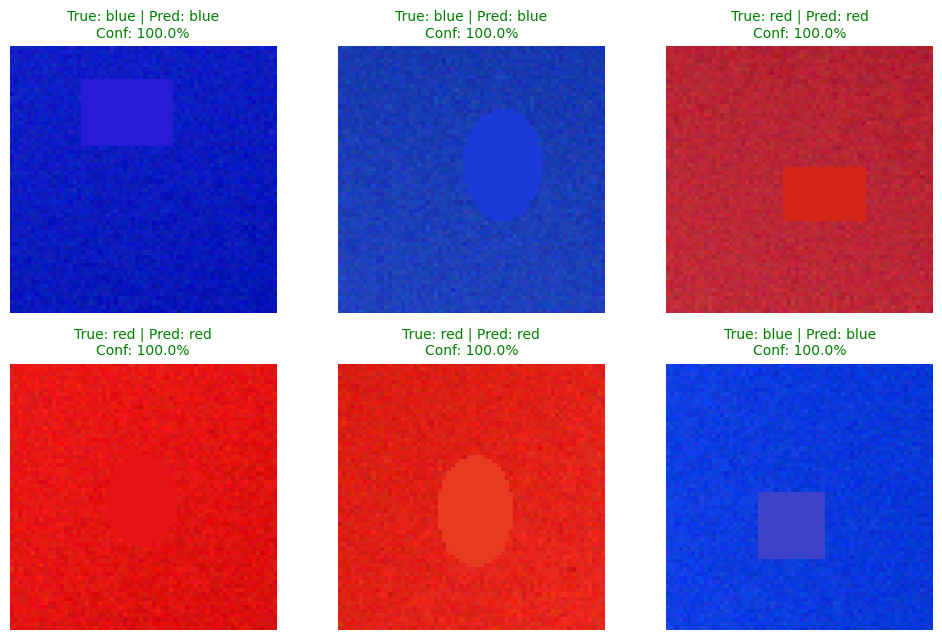

In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Dump (save) the trained CNN model
model_path = "red_blue_cnn_model.keras"
model.save(model_path)
print(f"Model saved to: {model_path}")

# 2. Load the dumped model back from disk
loaded_model = tf.keras.models.load_model(model_path)

# 3. Pick 3 random images from each class ('red' and 'blue')
data_dir = "red_blue_image_dataset"
IMG_SIZE = (64, 64)
class_names = sorted(os.listdir(data_dir))  # ['blue', 'red']

samples = []
for cls in class_names:
    cls_folder = os.path.join(data_dir, cls)
    for fname in random.sample(os.listdir(cls_folder), 3):
        samples.append((cls, os.path.join(cls_folder, fname)))

random.shuffle(samples)

# 4. Predict and display each image with its predicted class
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for ax, (true_label, img_path) in zip(axes.flatten(), samples):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)

    prob = loaded_model.predict(img_batch, verbose=0)[0][0]
    pred_label = class_names[1] if prob >= 0.5 else class_names[0]
    confidence = prob if prob >= 0.5 else (1.0 - prob)

    ax.imshow(img_array.astype("uint8"))
    ax.set_title(
        f"True: {true_label} | Pred: {pred_label}\nConf: {confidence * 100:.1f}%",
        color="green" if pred_label == true_label else "red",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# import numpy as np
# import tensorflow as tf

# # 1. Single image ka path dein (apni kisi bhi test image ka path daalein)
# img_path = "red_blue_image_dataset/Red/img_1.jpg"  # ya koi bhi bahar ki image

# # 2. Image ko load karke model ke size (64x64) mein resize karein
# img = tf.keras.utils.load_img(img_path, target_size=(64, 64))

# # 3. Image ko array mein badlein aur batch dimension add karein -> (1, 64, 64, 3)
# img_array = tf.keras.utils.img_to_array(img)
# img_array = np.expand_dims(img_array, axis=0)

# # 4. Prediction karein (Sigmoid 0 se 1 ke beech score dega)
# prob = model.predict(img_array)[0][0]

# # 5. Result print karein (class_names: ['Blue', 'Red'] alphabetical order mein)
# predicted_class = class_names[1] if prob >= 0.5 else class_names[0]
# confidence = prob if prob >= 0.5 else (1 - prob)

# print(f"Predicted Class: {predicted_class} (Confidence: {confidence * 100:.2f}%)")